In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Загружаем датасет

In [ ]:
df = pd.read_csv('/data.csv')
df.head()

,Price,Apartment type,Metro station,Minutes to metro,Region,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors,Renovation
0,6300000.0,Secondary,Опалиха,6.0,Moscow region,1.0,30.6,11.1,8.5,25.0,25,Cosmetic
1,9000000.0,Secondary,Павшино,2.0,Moscow region,1.0,49.2,20.0,10.0,6.0,15,European-style renovation
2,11090000.0,Secondary,Мякинино,14.0,Moscow region,1.0,44.7,16.2,13.1,10.0,25,Cosmetic
3,8300000.0,Secondary,Строгино,8.0,Moscow region,1.0,35.1,16.0,11.0,12.0,33,European-style renovation
4,6450000.0,Secondary,Опалиха,6.0,Moscow region,1.0,37.7,15.2,4.0,5.0,5,Without renovation


Данные

In [ ]:
df.info()
df.head()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22676 entries, 0 to 22675
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Price             22676 non-null  float64
 1   Apartment type    22676 non-null  object 
 2   Metro station     22676 non-null  object 
 3   Minutes to metro  22676 non-null  float64
 4   Region            22676 non-null  object 
 5   Number of rooms   22676 non-null  float64
 6   Area              22676 non-null  float64
 7   Living area       22676 non-null  float64
 8   Kitchen area      22676 non-null  float64
 9   Floor             22676 non-null  float64
 10  Number of floors  22676 non-null  int64  
 11  Renovation        22676 non-null  object 
dtypes: float64(7), int64(1), object(4)
memory usage: 2.1+ MB


,Price,Minutes to metro,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors
count,2.267600e+04,22676.000000,22676.000000,22676.000000,22676.000000,22676.000000,22676.000000,22676.000000
mean,3.612132e+07,11.888605,2.043129,71.966827,38.517953,12.594082,9.190466,16.556095
std,8.282561e+07,6.204457,1.523586,68.368608,38.124278,7.728074,7.549996,9.779297
min,1.150000e+06,0.000000,0.000000,6.000000,2.000000,1.000000,1.000000,1.000000
25%,7.068116e+06,7.000000,1.000000,37.400000,17.600000,8.600000,4.000000,11.000000
50%,1.134320e+07,11.000000,2.000000,53.300000,28.500000,10.600000,8.000000,16.000000
75%,2.479925e+07,15.000000,3.000000,77.140000,43.200000,14.500000,13.000000,20.000000
max,2.455020e+09,60.000000,12.000000,1117.000000,566.800000,122.000000,92.000000,97.000000


Удаляем выбросы

In [ ]:
cols = [                #Список колонок с которым работаем
    'Price',
    'Minutes to metro',
    'Number of rooms',
    'Area',
    'Living area',
    'Kitchen area',
    'Floor',
    'Number of floors'
]

df_clean = df.copy() #Копия исходного датафрейма для очистки

for col in cols:                      #Цикл по каждой колонке из списка
  Q1 = df_clean[col].quantile(0.25)   #1-й квартиль 25%
  Q3 = df_clean[col].quantile(0.75)   #2-й квартиль 75%
  IQR = Q3 - Q1                       #Межквартильный размах (разница)
  lower = Q1 - 1.5 * IQR              #Нижняя граница значений
  upper = Q3 + 1.5 * IQR              #Верхняя граница значений
  df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]      #Фильтруем датафрейм, оставляем только строки, где значение в колонке находится в диапазоне
  print(f"{col}: осталось {df_clean.shape[0]} строк после удаления выбросов")

print('До очистки', df.shape)
print('После очистки', df_clean.shape)

df = df_clean.copy() #Заменяем исходный датафрейм на очищенну версию

Price: осталось 19336 строк после удаления выбросов
Minutes to metro: осталось 19069 строк после удаления выбросов
Number of rooms: осталось 17925 строк после удаления выбросов
Area: осталось 17663 строк после удаления выбросов
Living area: осталось 17563 строк после удаления выбросов
Kitchen area: осталось 16333 строк после удаления выбросов
Floor: осталось 16118 строк после удаления выбросов
Number of floors: осталось 15811 строк после удаления выбросов
До очистки (22676, 12)
После очистки (15811, 12)


Что осталось после очистки

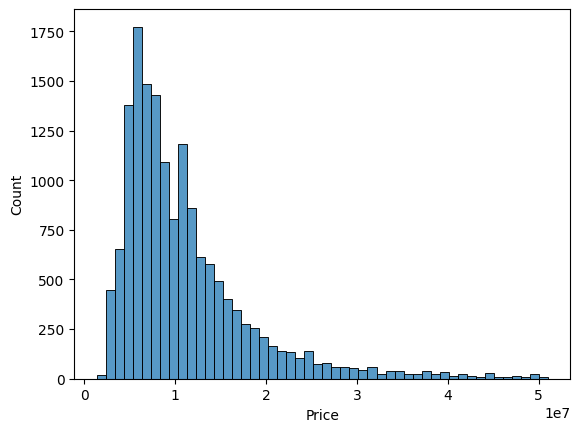

,Price,Minutes to metro,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors
count,1.581100e+04,15811.000000,15811.000000,15811.000000,15811.000000,15811.000000,15811.000000,15811.000000
mean,1.113783e+07,11.909683,1.491177,47.043570,25.727494,9.890766,8.413446,15.105243
std,7.391240e+06,5.314291,0.992047,18.105657,11.012564,3.083332,5.685987,5.687191
min,1.420000e+06,0.000000,0.000000,8.400000,2.000000,2.100000,1.000000,1.000000
25%,6.194288e+06,8.000000,1.000000,35.000000,16.400000,8.100000,3.000000,11.000000
50%,8.902842e+06,12.000000,2.000000,44.430000,24.700000,10.000000,8.000000,15.000000
75%,1.350000e+07,15.000000,2.000000,60.290000,33.200000,11.800000,12.000000,20.000000
max,5.100000e+07,28.000000,3.000000,100.750000,59.000000,18.100000,26.000000,33.000000


In [ ]:
sns.histplot(df['Price'], bins = 50) #Посмотреть на распределение цен
plt.show()

df.describe()

Дорогие станции метро

In [ ]:
metro_price = df_clean.groupby('Metro station')['Price'].mean().sort_values(ascending=False)
metro_price.head(10)

,Price
Metro station,
Воробьёвы горы,5.024800e+07
Арбатская,5.000000e+07
Сретенский бульвар,4.800000e+07
Пушкинская,4.618425e+07
Выставочная,4.500000e+07
Марксистская,4.500000e+07
Добрынинская,4.450000e+07
Третьяковская,4.275000e+07
Арбатская,4.232500e+07


Дорогие средние и дешёвые станции

In [ ]:
q1 = metro_price.quantile(0.33) #Квантиль 33%
q3 = metro_price.quantile(0.67) #Квантиль 67%

def categorize_metro(station):            #Определяем функцию для категоризации станций метро по цене
  price = metro_price.get(station, None)  #Средняя цена для конкретной станции, если нет none
  if price is None:                       #Если цена не найдена метка Unknown
    return 'Unknown'
  elif price <= q1:
    return 'Cheap'
  elif price <= q3:
    return 'Medium'
  else:
    return 'Expensive'

df_clean['Metro category'] = df_clean['Metro station'].apply(categorize_metro)  #Применяем функцию к каждой станции, результат в новую колонку

In [ ]:
df_clean['Metro station'] = df_clean['Metro station'].str.strip() #Очищаем названия от пробелов

Новая категория метро

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()                                                           #Создаём экземпляр класса Лейбл
df_clean['Metro category'] = le.fit_transform(df_clean['Metro category'])     #Преобразуем категориальные значения в числовые

In [ ]:
df_clean[['Price', 'Metro category', 'Minutes to metro']].corr()              #Корреляция между 3-мя признаками, возвращает матрицу

,Price,Metro category,Minutes to metro
Price,1.000000,0.476259,-0.018243
Metro category,0.476259,1.000000,-0.016949
Minutes to metro,-0.018243,-0.016949,1.000000


Коэффиценты для метро

In [ ]:
metro_price = df_clean.groupby('Metro station')['Price'].mean().reset_index()             #Группируем данные по станция метро, вычисляем среднюю цену, преобразуем результат обратно

median_price = metro_price['Price'].median()                                               #Вычисляем медианную цену среди всех станций

metro_price['Coef'] = metro_price['Price'] / median_price                                   #Новый столбец, рассчитываем коэф цены к медианной

metro_price = metro_price.sort_values(by='Coef', ascending=False).reset_index(drop=True)    #Сортируем станции по убыванию, обновляем индексы после сортировки

Предсказание цены с учётом метро

In [ ]:
def predict_price(features, station=None):                    #Функция для предсказания цены квартиры, словарь с характеристиками и операционный параметр

  base_price = model.predict([list(features.values())])[0]    #Получаем базовую цену, преобразуем словарь в список, берём элемент из массива предсказаний

  if station in metro_price:      #Есть ли указанная станция в датафрейме
    coef = metro_price[station]   #Если найдена берём её коэф
  else:
    coef = 1.0                    #Если нет, испоьзуем 1
  return base_price * coef        #Возвращаем итоговую цену

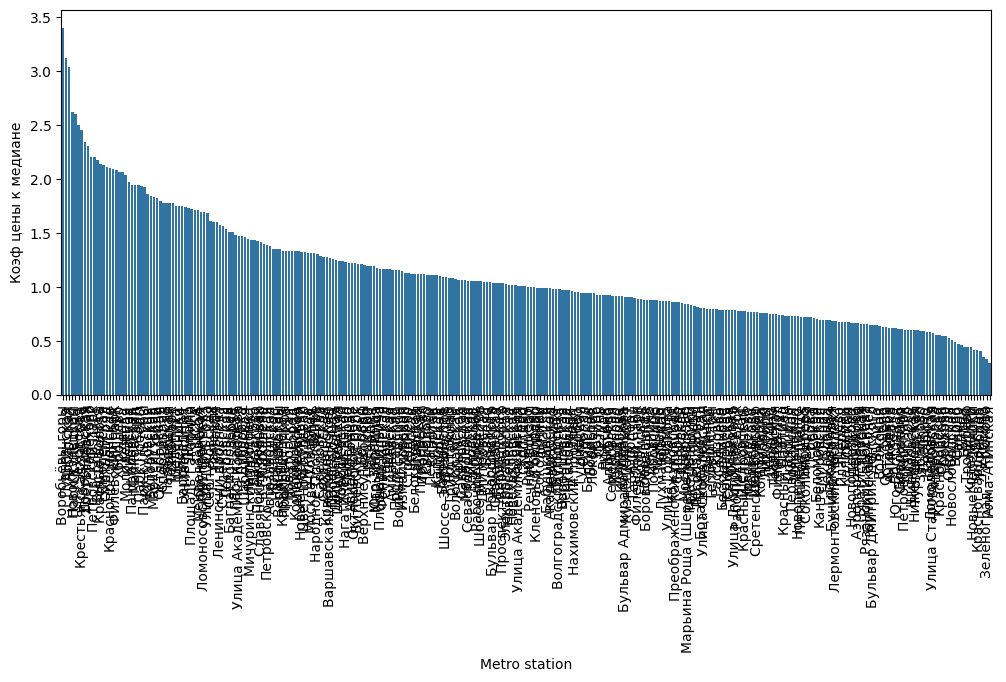

In [ ]:
plt.figure(figsize=(12,5))                                    #Фигура для графика
sns.barplot(x='Metro station', y='Coef', data=metro_price)    #Столбчатая диаграмма
plt.xticks(rotation=90)
plt.ylabel('Коэф цены к медиане')
plt.show()

In [ ]:
print(f'All station: {metro_price.shape[0]}') #Выводим общее кол-во станций в датафрейме
metro_price.head(296)

All station: 296


,Metro station,Price,Coef
0,Воробьёвы горы,5.024800e+07,3.396055
1,Пушкинская,4.618425e+07,3.121403
2,Арбатская,4.488333e+07,3.033479
3,Новокузнецкая,3.866810e+07,2.613417
4,Парк Культуры,3.850000e+07,2.602056
...,...,...,...
291,Красногвардейская,6.049446e+06,0.408857
292,Жулебино,5.992173e+06,0.404986
293,Косино,5.150000e+06,0.348067
294,Зеленоград — Крюково,4.903900e+06,0.331434


In [ ]:
num_stations = df_clean['Metro station'].nunique()    #Считаем кол-во уникальных станций в очищенном датафрейме
print(num_stations)                                   #Кол-во уникальных станций

station_list = df_clean['Metro station'].unique()     #Список всех уникальных названий
print(station_list)                                   #Выводим список станций

296
['Опалиха' 'Павшино' 'Мякинино' 'Строгино' 'Нахабино' 'Красногорская'
 'Аникеевка' 'Волоколамская' 'Пенягино' 'Митино' 'Тушинская'
 'Пятницкое шоссе' 'ВДНХ' 'Филатов Луг' 'Минская' 'Динамо' 'Бауманская'
 'Славянский бульвар' 'Шелепиха' 'Давыдково' 'Пушкинская' 'Технопарк'
 'Преображенская площадь' 'Красные ворота' 'Волгоградский проспект'
 'Молодёжная' 'Сходненская' 'Прокшино' 'Окружная' 'Спортивная' 'Фили'
 'Саларьево' 'Бибирево' 'Печатники' 'Новогиреево' 'Бульвар Рокоссовского'
 'Филёвский парк' 'Смоленская' 'Рязанский проспект' 'Профсоюзная'
 'Панфиловская' 'Выставочная' 'Парк Победы' 'Багратионовская' 'Крылатское'
 'Белорусская' 'Народное Ополчение' 'Стахановская' 'Полежаевская'
 'Щёлковская' 'Солнцево' 'Новопеределкино' 'Карамышевская' 'Балтийская'
 'Рижская' 'Угрешская' 'Селигерская' 'Маяковская' 'ЗИЛ' 'Улица 1905 года'
 'Войковская' 'Таганская' 'Курская' 'Ботанический сад' 'Локомотив'
 'Пражская' 'Водный стадион' 'Перерва' 'Сокольники' 'Коммунарка'
 'Царицыно' 'Бунинская алл

Ремонт

In [ ]:
df_clean['Renovation'] = df_clean['Renovation'].str.strip().str.lower()               #Удаляем пробелы и переводим в нижий регистр
df_clean['Renovation'] = df_clean['Renovation'].str.replace(r'\s+', ' ', regex=True)  #Заменяем множественные пробелы на одиночные

In [ ]:
repair_price = df_clean.groupby('Renovation')['Price'].mean().reset_index()           #Группируем данные по типу ремонта, вычисляем среднюю цену, пребразуем результат в датафрейм

median_repair = repair_price['Price'].median()                                        #Вычисляем медианную цену среди всех категорий ремонта

repair_price['Coeff'] = repair_price['Price'] / median_repair                         #Новый столбец, рассчитываем коэфф

repair_price = repair_price.sort_values(by='Coeff', ascending=False).reset_index(drop=True) #Сортируем по убыванию

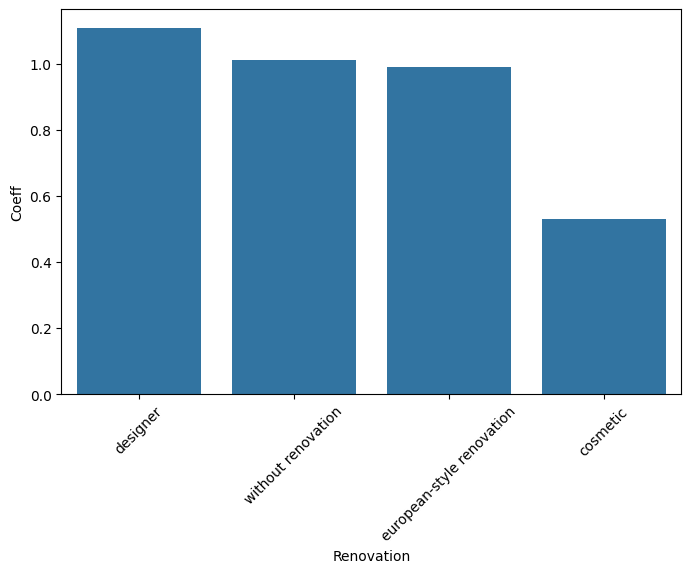

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Renovation', y='Coeff', data=repair_price)
plt.xticks(rotation=45)
plt.show()

In [ ]:
print(repair_price.shape[0])      #Выводим количество уникальных категорий ремонта
display(repair_price)             #Отображаем датафрейм

4


,Renovation,Price,Coeff
0,designer,1.853991e+07,1.108613
1,without renovation,1.691046e+07,1.011178
2,european-style renovation,1.653659e+07,0.988822
3,cosmetic,8.855242e+06,0.529508


Сама нейронка

In [ ]:
!pip install catboost --quiet                                                    #Устанавливаем библиотеку

from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

metro_coef = df.groupby('Metro station')['Price'].mean().to_dict()               #Создаём словарь коэффициентов для станций метро, считаем средние цены
df['Metro_coef']=df['Metro station'].map(metro_coef)                             #Добавляем новый признак, названия станций в числовые коэф

X = df[['Area', 'Number of rooms', 'Metro_coef', 'Minutes to metro', 'Floor']]   #Выбираем признаки для модели
y = np.log1p(df['Price'])                                                        #Целевая переменная, логарифмируем

X_train, X_test, y_train, y_test = train_test_split(                             #Разделяем данные на обучающую и тестовую выборки
    X, y, test_size=0.2, random_state=42                                         #20% данных для теста
)

model = CatBoostRegressor(                                                       #Модель с параметрами
    iterations=1500,                                                             #Количество итераций, деревьев
    learning_rate=0.03,                                                          #Скорость обучения
    depth=10,                                                                    #Глубина деревьев
    l2_leaf_reg=4,                                                               #Коэф регуляризации
    loss_function='RMSE',                                                        #Функции потерь
    eval_metric='RMSE',                                                          #Метрика для оценки
    random_seed=42,                                                              #Для воспроизводимости результатов
    verbose=200                                                                  #Выводить прогресс каждые 200 итераций
)

model.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)      #Обучаем модель, выборка, валидационная выборка, использовать лучшую модель по валидации

y_pred = model.predict(X_test)                                                   #Предсказания в логарифмической шкале
y_pred_real = np.expm1(y_pred)                                                   #Обратное преобразование в реальные цены
y_test_real = np.expm1(y_test)                                                   #Реальные цены из теста

mae=mean_absolute_error(y_test_real, y_pred_real)                                #Метрики качества, средняя абсолютная ошибка
rmse=np.sqrt(mean_squared_error(y_test_real, y_pred_real))                       #Корень из MSE

print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.3 MB/s eta 0:00:00
0:	learn: 0.5511853	test: 0.5704245	best: 0.5704245 (0)	total: 62.8ms	remaining: 1m 34s
200:	learn: 0.1606531	test: 0.1632254	best: 0.1632254 (200)	total: 2.35s	remaining: 15.2s
400:	learn: 0.1441104	test: 0.1539253	best: 0.1539253 (400)	total: 6.77s	remaining: 18.5s
600:	learn: 0.1326214	test: 0.1489663	best: 0.1489663 (600)	total: 9.39s	remaining: 14s
800:	learn: 0.1243505	test: 0.1457614	best: 0.1457614 (800)	total: 11.7s	remaining: 10.2s
1000:	learn: 0.1180690	test: 0.1434402	best: 0.1434402 (1000)	total: 14s	remaining: 6.96s
1200:	learn: 0.1124391	test: 0.1417564	best: 0.1417510 (1196)	total: 16.2s	remaining: 4.03s
1400:	learn: 0.1075753	test: 0.1404556	best: 0.1404556 (1400)	total: 19.6s	remaining: 1.39s
1499:	learn: 0.1053911	test: 0.1398229	best: 0.1398229 (1499)	total: 22s	remaining: 0us

bestTest = 0.1398229407
bestIteration = 1499

MAE: 1202578.17
RMSE: 2388961.68


In [ ]:
print(metro_price.head(256))

df_metro=metro_price.copy()                                                                      #Копия датафрейма, сохраняем данные
metro_price = df_clean.groupby('Metro station')['Price'].agg(['mean', 'count']).reset_index()    #Среднее значение цены и количество записей
df_metro.columns = ['Metro station', 'Metro_coef', 'Count']                                      #Новые названия столбцов

df_metro.to_csv('/content/metro_coefs.csv', index=False)                                         #Сохраняем данные


        Metro station         Price      Coef
0      Воробьёвы горы  5.024800e+07  3.396055
1          Пушкинская  4.618425e+07  3.121403
2           Арбатская  4.488333e+07  3.033479
3       Новокузнецкая  3.866810e+07  2.613417
4       Парк Культуры  3.850000e+07  2.602056
..                ...           ...       ...
251    Новоподрезково  9.856642e+06  0.666170
252          Щербинка  9.826039e+06  0.664101
253  Аэропорт Внуково  9.801580e+06  0.662448
254     Братиславская  9.732664e+06  0.657791
255           Трубная  9.660000e+06  0.652880

[256 rows x 3 columns]


Полезные графики

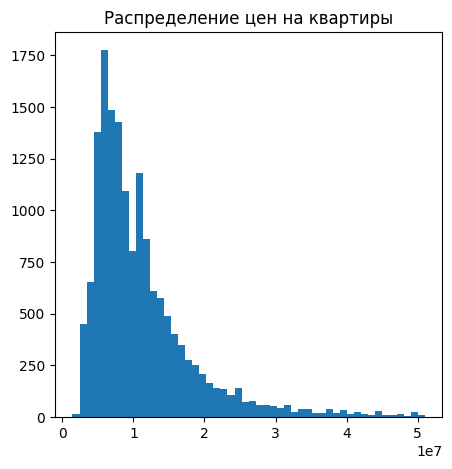

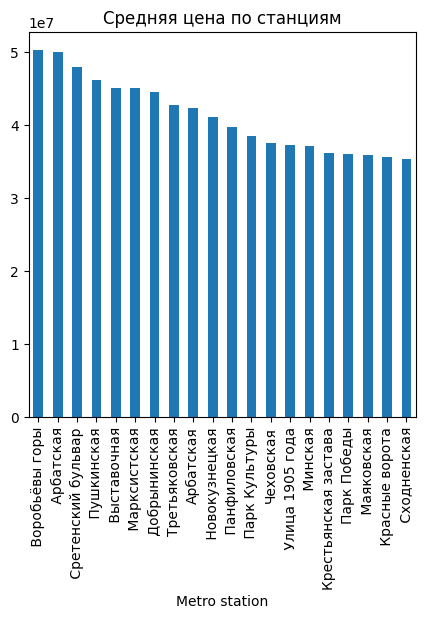

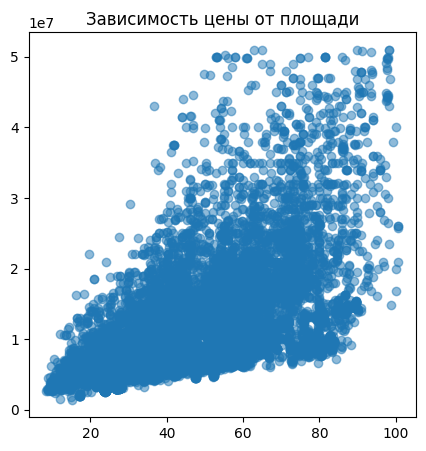

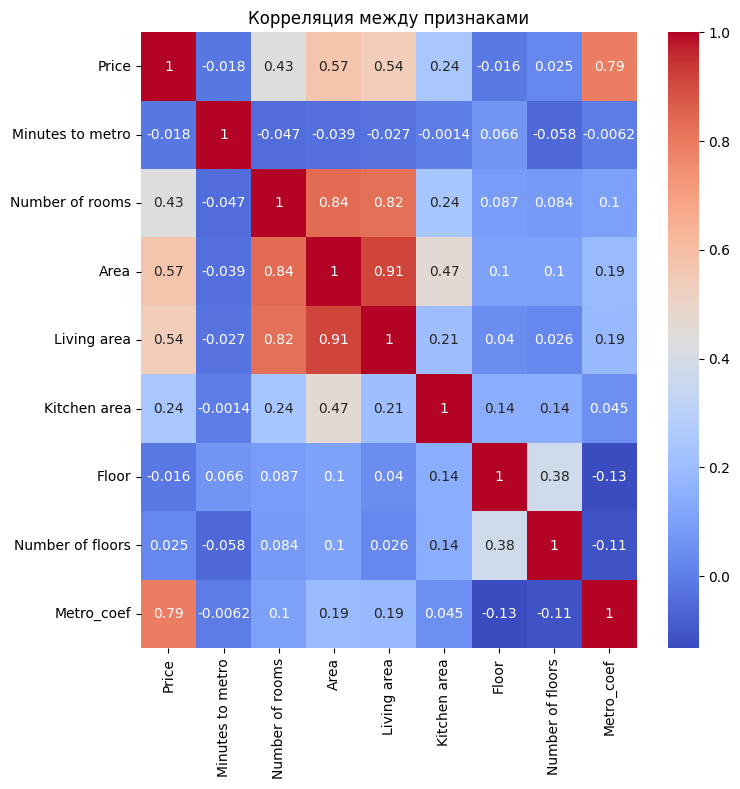

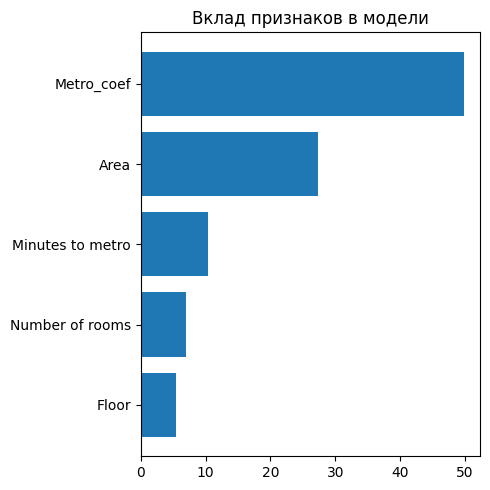

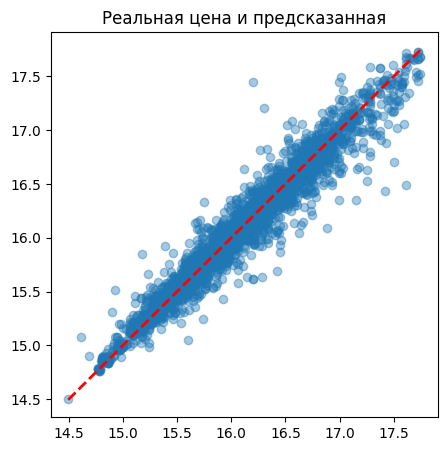

In [ ]:
import seaborn as sns

plt.figure(figsize=(5,5))
plt.hist(df['Price'], bins=50)
plt.title('Распределение цен на квартиры')

avg_price_metro = df.groupby('Metro station')['Price'].mean().sort_values(ascending=False).head(20)
plt.figure(figsize=(5,5))
avg_price_metro.plot(kind='bar')
plt.title('Средняя цена по станциям')
plt.xticks(rotation=90)

plt.figure(figsize=(5,5))
plt.scatter(df['Area'], df['Price'], alpha=0.5)
plt.title('Зависимость цены от площади')

plt.figure(figsize=(8,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Корреляция между признаками')

feature_importance = pd.DataFrame({
    'Feature': model.feature_names_,
    'Importance': model.get_feature_importance()
}).sort_values(by='Importance', ascending=True)
plt.figure(figsize=(5,5))
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.title('Вклад признаков в модели')
plt.tight_layout()

# df['predicted_price']=model.predict(df[['Area', 'Number of rooms', 'Metro_coef', 'Minutes to metro', 'Floor']])
# metro_mae=(
#     df.groupby('Metro station')
#     .apply(
#         lambda x: mean_absolute_error(x['Price'], x['predicted_price']),
#         include_groups=False
#         )
#     .sort_values(ascending=False).head(20)
# )
# plt.figure(figsize=(5,5))
# metro_mae.plot(kind='bar')
# plt.title('Средняя ошибка MAE по станциям')
# plt.xticks(rotation=90)
# plt.tight_layout()

plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()],
  [y_test.min(), y_test.max()],
  'r--', lw=2)
plt.title('Реальная цена и предсказанная')
plt.show()

Полезные параметры

In [ ]:
y_pred=np.expm1(model.predict(X_test))
y_test_real=np.expm1(y_test)
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
r2=r2_score(y_test_real, y_pred)
print(f'R2: {r2:.2f}')
print('-----------------')

feature_importances = model.get_feature_importance()
for f, imp in sorted(zip(X.columns, feature_importances), key=lambda x: x[1], reverse=True):
  print(f'{f}: {imp:.2f}')
print('-----------------')

comparison=pd.DataFrame({
    'Реальная цена': y_test_real,
    'Предсказанная цена': y_pred,
})
comparison['Ошибка (руб.)']=abs(comparison['Реальная цена']-comparison['Предсказанная цена'])
comparison['Ошибка %']=(comparison['Ошибка (руб.)']/comparison['Реальная цена'])*100
comparison=comparison.round(0)
comparison.head(10).style.format({
    'Реальная цена': '{:,.0f}',
    'Предсказанная цена': '{:,.0f}',
    'Ошибка (руб.)': '{:,.0f}',
    'Ошибка %': '{:,.0f}'
})

MAE: 1202578.17
RMSE: 2388961.68
R2: 0.90
-----------------
Metro_coef: 49.84
Area: 27.38
Minutes to metro: 10.33
Number of rooms: 6.97
Floor: 5.49
-----------------


,Реальная цена,Предсказанная цена,Ошибка (руб.),Ошибка %
20764,"4,435,580","4,069,709","365,871",8
194,"16,300,000","12,064,253","4,235,747",26
4777,"16,200,000","17,922,954","1,722,954",11
16725,"11,138,750","10,797,247","341,503",3
21410,"4,732,446","4,742,862","10,416",0
5739,"13,490,000","13,867,763","377,763",3
14025,"7,408,800","8,094,365","685,565",9
6339,"26,455,100","26,166,001","289,099",1
95,"7,650,000","7,762,385","112,385",1
21247,"15,009,120","14,714,370","294,750",2


Карта Москвы

In [ ]:
dx = pd.read_csv('/metrocord.csv')
df_metro = pd.read_csv('/content/metro_coefs.csv')

print(dx.head())

print(df_metro.head())

print(df_metro.to_string())

          Line LineColor               Name   Latitude  Longitude  Order
0  Калининская    FFCD1C         Новокосино  55.745113  37.864052      0
1  Калининская    FFCD1C        Новогиреево  55.752237  37.814587      1
2  Калининская    FFCD1C             Перово  55.750980  37.784220      2
3  Калининская    FFCD1C  Шоссе энтузиастов  55.758090  37.751703      3
4  Калининская    FFCD1C       Авиамоторная  55.751933  37.717444      4
    Metro station    Metro_coef     Count
0  Воробьёвы горы  5.024800e+07  3.396055
1      Пушкинская  4.618425e+07  3.121403
2       Арбатская  4.488333e+07  3.033479
3   Новокузнецкая  3.866810e+07  2.613417
4   Парк Культуры  3.850000e+07  2.602056
                     Metro station    Metro_coef     Count
0                   Воробьёвы горы  5.024800e+07  3.396055
1                       Пушкинская  4.618425e+07  3.121403
2                        Арбатская  4.488333e+07  3.033479
3                    Новокузнецкая  3.866810e+07  2.613417
4              

In [ ]:
import pandas as pd
import folium
from folium.plugins import HeatMap

# Слияние датафреймов
map_df = pd.merge(
    df_metro,
    dx,
    left_on='Metro station',
    right_on='Name',
    how='inner'
)

# Очищаем названия станций от пробелов
map_df['Metro station'] = map_df['Metro station'].str.strip()
map_df['Name'] = map_df['Name'].str.strip()

# Удаляем дубликаты
map_df = map_df.drop_duplicates(subset='Metro station', keep='first')

# Проверяем типы данных
print("Типы данных в map_df:")
print(map_df.dtypes)

# Проверяем наличие всех необходимых столбцов
required_columns = ['Metro station', 'Latitude', 'Longitude', 'Count']
for col in required_columns:
    if col not in map_df.columns:
        print(f"Критический столбец {col} отсутствует!")
        break

# Создание карты
m = folium.Map(location=[55.7558, 37.6173], zoom_start=11)

# Создаём маркеры
def colorize(coef):
    if coef >= map_df['Count'].quantile(0.75):
        return 'red'
    elif coef <= map_df['Count'].quantile(0.25):
        return 'green'
    else:
        return 'orange'

#Используем прямой доступ к данным через индексы
for index in range(len(map_df)):
    try:
        row = map_df.iloc[index]
        folium.CircleMarker(
            location=[row['Latitude'], row['Longitude']],
            radius=5,
            popup=f"{row['Metro station']} - коэффициент {row['Count']:.3f}",
            color=colorize(row['Count']),
            fill=True,
            fill_opacity=0.9
        ).add_to(m)
    except KeyError as e:
        print(f"Ошибка в строке {index}: отсутствует столбец {e}")
    except Exception as e:
        print(f"Ошибка в строке {index}: {e}")

# Подготавливаем данные для карты
heat_data = map_df[['Latitude', 'Longitude', 'Count']].values.tolist()

# Добавляем тепловую карту
HeatMap(
    heat_data,
    radius=80,
    blur=20,
    min_opacity=0.2,
    gradieant={
        0.0: 'blue',
        0.25: 'cyan',
        0.5: 'lime',
        0.75: 'yellow',
        1.0: 'red'
    }
).add_to(m)

from branca.element import Template, MacroElement

template = """
{% macro html(this, kwargs) %}
  <div style="position: fixed;
              bottom: 50px; left: 25px;
              width: 120px; height: 20px;
              border: 1px solid black;
              z-index: 9999;
              background-color: white;">
  Тепловая карта интенсивности
  </div>
{% endmacro %}
"""

macro = MacroElement()
macro._template = Template(template)
m.get_root().add_child(macro)

m

m.save("metro_map.html")

Типы данных в map_df:
Metro station     object
Metro_coef       float64
Count            float64
Line              object
LineColor         object
Name              object
Latitude         float64
Longitude        float64
Order              int64
dtype: object


Мини приложение

In [ ]:
!pip install streamlit catboost

model.save_model('catboost_model.cbm')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 74.2 MB/s eta 0:00:00


In [ ]:
%%writefile app.py
import streamlit as st
from catboost import CatBoostRegressor
import pandas as pd
import numpy as np

model = CatBoostRegressor()
model.load_model('catboost_model.cbm')

st.title('Предсказание цен в Москве')
st.write('Введите параметры квартиры')

metro_coefs=pd.read_csv('/content/metro_coefs.csv')
metro_names=metro_coefs['Metro station'].tolist()

area = st.number_input('Площадь', min_value=10.0, max_value=300.0, value=50.0)
rooms  = st.number_input('Комнаты', min_value=1, max_value=10, value=2)
minutes = st.number_input('Минуты до метро', min_value=0, max_value=60, value=10)
floor = st.number_input('Этаж', min_value=1, max_value=50, value=5)

selected_metro=st.selectbox('Станция метро', metro_names)
metro_coef=metro_coefs.loc[
    metro_coefs['Metro station'] == selected_metro, 'Metro_coef'
].values[0]

data = pd.DataFrame({
    'Area': [area],
    'Number of rooms': [rooms],
    'Metro_coef': [metro_coef],
    'Minutes to metro': [minutes],
    'Floor': [floor]
})

if st.button('Предсказать цену'):
  pred = np.expm1(model.predict(data)[0])
  st.success(f'Примерная цена квартиры: **{pred:,.0f} ₽**')

Writing app.py


In [ ]:
!pip install streamlit cloudflared --quiet

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 kB 1.9 MB/s eta 0:00:00


In [ ]:
import joblib
joblib.dump(model, "model.pkl")

['model.pkl']

In [ ]:
!streamlit run app.py & npx cloudflared tunnel --url http://localhost:8501

⠙⠹

⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦2026-03-03T07:10:59Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-03-03T07:10:59Z INF Requesting new quick Tunnel on trycloudflare.com...

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.205.147:8501

2026-03-03T07:11:03Z INF +--------------------------------------------------------------------------------------------+
2026-03-